In [1]:
# pip install -r requirements.txt 
print('Môi trường sẵn sàng')

Môi trường sẵn sàng


In [2]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.tree import plot_tree
from mlxtend.frequent_patterns import fpgrowth, association_rules

RANDOM_STATE = 42
BASE = Path("..") if Path.cwd().name == "notebooks" else Path(".")
DATA = BASE / "data"
FIG_DIR = BASE / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RAW_PATH = DATA / "raw_data.csv"
CLEAN_PATH = DATA / "clean_data.csv"

def save_fig(filename, fig=None):
    if fig is None:
        fig = plt.gcf()

    save_path = FIG_DIR / filename

    fig.savefig(
        save_path,
        dpi=150,
        bbox_inches="tight"
    )
    print(f"Đã lưu biểu đồ: {save_path}")


In [3]:
#Đọc csv và kiểm tra cấu trúc
if not RAW_PATH.exists():
    raise FileNotFoundError(f"Chưa thấy {RAW_PATH}. Hãy đặt CSV vào thư mục data.")
raw = pd.read_csv(RAW_PATH)
print("Shape:", raw.shape)
display(raw.head())
display(pd.DataFrame({"column": raw.columns,
                      "dtype": [str(raw[c].dtype) for c in raw.columns],
                      "missing": [raw[c].isna().sum() for c in raw.columns]}))

Shape: (1160, 15)


,Job_ID,Source,Job_Title,Company,Location_Raw,Salary_Raw,Experience_Raw,Skills_Raw,Description_Raw,Requirements_Raw,Benefits_Raw,Date_Posted,Keyword,URL_Goc,Timestamp
0,itviec_0143,itviec,"Middle, Senior FullStack Developer Java, Go",MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Develop...",- Tốt nghiệp Đại học các chuyên ngành Công ngh...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2026-10-23,data analyst,https://itviec.com/it-jobs/middle-senior-fulls...,2026-11-16T20:03:57
1,itviec_5434,itviec,AI Software Engineer Python/Go/C/C++ AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go...,- Tốt nghiệp Đại học các chuyên ngành: Công ng...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2026-10-23,data analyst,https://itviec.com/it-jobs/ai-software-enginee...,2026-11-16T20:04:00
2,itviec_5127,itviec,Agentic Engineer Python/Go/C/C++ Backend AI A...,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Python, FastAPI, Golang, AI, Microservices, C++",2026TD450887 - Agentic Engineer (Python/Go/C/C...,- Tốt nghiệp Đại học các chuyên ngành: Công ng...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2026-10-23,data analyst,https://itviec.com/it-jobs/agentic-engineer-py...,2026-11-16T20:04:03
3,itviec_3448,itviec,"Data Analyst SQL, PowerBI, Looker",ETC Technology Systems,"Tòa 319 BQP, số 63 Lê Văn Lương, Quận Cầu Giấy...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Data Analysis, Data modeling, Governance, Risk...",MÔ TẢ CÔNG VIỆC:\nNhận nhiệm vụ và báo cáo trự...,Tốt nghiệp Đại học các ngành liên quan: Công n...,"Chế độ lương thưởng hấp dẫn,\nChế độ BHYT, BHX...",2026-10-28,data analyst,https://itviec.com/it-jobs/data-analyst-sql-po...,2026-11-16T20:04:07
4,itviec_1945,itviec,Senior Data Analyst,GFT Technologies Vietnam,"29A Nguyen Dinh Chieu, Quận 1, Hồ Chí Minh | 1...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","SQL, Python, Tableau, AWS",Role Summary\nWe are looking for a Senior Data...,Required Skills and Experience\nAt least 5 yea...,HR benefits\nCompetitive salary\nSalary band p...,2026-11-10,data analyst,https://itviec.com/it-jobs/senior-data-analyst...,2026-11-16T20:04:11


,column,dtype,missing
0,Job_ID,str,0
1,Source,str,0
2,Job_Title,str,0
3,Company,str,0
4,Location_Raw,str,0
5,Salary_Raw,str,0
6,Experience_Raw,str,51
7,Skills_Raw,str,145
8,Description_Raw,str,0
9,Requirements_Raw,str,11


In [4]:
COLUMN_MAP = {
    "job_title": "Job_Title", "company": "Company",
    "location": "Location_Raw", "salary": "Salary_Raw",
    "experience": "Experience_Raw", "skills_raw": "Skills_Raw",
    "description": "Description_Raw", "requirements": "Requirements_Raw",
    "benefits": "Benefits_Raw", "url": "URL_Goc",
    "timestamp": "Timestamp", "source": "Source"
}
rename = {}
for standard, original in COLUMN_MAP.items():
    if original in raw.columns: rename[original] = standard
    else: print(f"CẦN KIỂM TRA: không thấy cột {original} cho {standard}")
df = raw.rename(columns=rename).copy()
print("Thiếu cột cốt lõi:", [c for c in ["job_title","company","location","salary","experience","description","url","timestamp"] if c not in df.columns])

Thiếu cột cốt lõi: []


In [5]:
# Kiểm tra chất lượng, lọc dữ liệu & khử trùng
print("Dòng ban đầu:", len(df))
n0 = len(df)

# Khử trùng theo URL
if "url" in df.columns:
    print("URL trùng:", df["url"].duplicated().sum())
    df = df.drop_duplicates(subset=["url"], keep="first")
else:
    df = df.drop_duplicates()
print("Dòng sau khử trùng URL:", len(df))

# Lọc tin không thuộc IT/Data
REL_TITLE = re.compile(
    r"data|dữ liệu|\bbi\b|power ?bi|analyst|phân tích|machine|\bml\b|\bai\b|\betl\b|python|sql|scientist|"
    r"software|developer|lập trình|backend|frontend|full ?stack|devops|cloud|\bit\b|cntt|kỹ sư|engineer|"
    r"\bqa\b|\btest|security|an ninh mạng|mlops|big ?data|automation", re.I)
NON_IT = re.compile(r"kế toán|accountant|sales|kinh doanh|marketing|nhân sự|hr\b|logistics|sản xuất|"
                    r"tài chính|finance|bim|mep|cơ khí|xây dựng|thu mua|pháp chế|rủi ro", re.I)
_FILTER_SKILLS = ["python","java","c++","javascript","r","scala","sql","excel","power bi","tableau","looker",
                  "pandas","numpy","machine learning","deep learning","pytorch","tensorflow","scikit-learn",
                  "opencv","computer vision","nlp","spark","hadoop","airflow","etl","kafka","dbt","aws","azure",
                  "gcp","docker","kubernetes","jenkins","linux","mysql","postgresql","sql server","mongodb",
                  "redis","oracle"]
_FILTER_PATS = [re.compile(r"(?<![\w+#])" + re.escape(s) + r"(?![\w+#])") for s in _FILTER_SKILLS]

def _strip_tags(x):
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", str(x) if pd.notna(x) else ""))

_txt = (df["job_title"].fillna("") + " " + df["skills_raw"].apply(_strip_tags) + " "
        + df["description"].apply(_strip_tags) + " " + df["requirements"].apply(_strip_tags)).str.lower()
_n_skill = _txt.apply(lambda t: sum(bool(p.search(t)) for p in _FILTER_PATS))

title = df["job_title"].fillna("")
is_it = ~title.str.contains(NON_IT) & (title.str.contains(REL_TITLE) | (_n_skill >= 4))
print(f"Lọc tin lạc đề IT/Data: bỏ {(~is_it).sum()} dòng")
df = df[is_it].copy()
print("Dòng sau lọc IT/Data:", len(df))

# Khử trùng theo nội dung
def _city_key(loc):
    first = str(loc).split("|")[0].lower()
    for name, pat in [("Remote", r"remote|work from home|làm việc từ xa"),
                      ("TP.HCM", r"hồ chí minh|ho chi minh|hcm|sài gòn|sai gon"),
                      ("Hà Nội", r"hà nội|ha noi|hanoi"),
                      ("Đà Nẵng", r"đà nẵng|da nang")]:
        if re.search(pat, first):
            return name
    return "Khác"

_dup_key = pd.DataFrame({
    "t": df["job_title"].fillna("").str.strip().str.lower(),
    "c": df["company"].fillna("").str.strip().str.lower(),
    "l": df["location"].apply(_city_key),
})
before = len(df)
df = df[~_dup_key.duplicated()].copy()
print(f"Khử trùng Title+Company+City: bỏ {before - len(df)} dòng")
print(f"Tổng: {n0} -> {len(df)} dòng (bỏ {n0 - len(df)})")

missing = df.isna().sum().sort_values(ascending=False).to_frame("missing")
missing["percent"] = (missing["missing"]/max(len(df),1)*100).round(2)
display(missing)


Dòng ban đầu: 1160
URL trùng: 0
Dòng sau khử trùng URL: 1160
Lọc tin lạc đề IT/Data: bỏ 547 dòng
Dòng sau lọc IT/Data: 613
Khử trùng Title+Company+City: bỏ 11 dòng
Tổng: 1160 -> 602 dòng (bỏ 558)


,missing,percent
skills_raw,65,10.80
benefits,24,3.99
experience,16,2.66
requirements,10,1.66
job_title,0,0.00
source,0,0.00
Job_ID,0,0.00
salary,0,0.00
location,0,0.00
company,0,0.00


In [6]:
# Cleaning
import json as _json

for c in ["job_title","company","location","salary","experience","skills_raw","description","requirements","benefits","url","source"]:
    if c in df.columns: df[c] = df[c].where(df[c].notna(), "").astype(str).str.strip()

def clean_text(x):
    x = re.sub(r"<[^>]+>", " ", str(x or ""))
    x = re.sub(r"https?://\S+", " ", x)
    return re.sub(r"\s+", " ", x).strip()

for c in ["job_title","skills_raw","description","requirements","benefits"]:
    if c in df.columns: df[c+"_clean"] = df[c].apply(clean_text)

def norm_location(x):
    s = clean_text(x).lower()
    if not s: return "Khác/Chưa rõ"
    if any(k in s for k in ["hồ chí minh","ho chi minh","hcm","hcmc","sài gòn","saigon","thủ đức","thu duc"]): return "TP.HCM"
    if any(k in s for k in ["hà nội","ha noi","hanoi"]): return "Hà Nội"
    if any(k in s for k in ["đà nẵng","da nang","danang"]): return "Đà Nẵng"
    if any(k in s for k in ["remote","work from home","làm việc từ xa"]): return "Remote"
    return "Tỉnh thành khác"

if "location" in df.columns: df["Location_Normalized"] = df["location"].apply(norm_location)

def exp_years(x):
    raw_str = str(x or "").strip()
    if not raw_str or raw_str.lower() == "nan": return np.nan
    # monthsOfExperience -> quy đổi ra năm
    try:
        obj = _json.loads(raw_str)
        if isinstance(obj, dict) and obj.get("monthsOfExperience") is not None:
            return round(float(obj["monthsOfExperience"]) / 12.0, 2)
    except (ValueError, TypeError):
        pass
    s = raw_str.lower()
    if any(k in s for k in ["không yêu cầu","khong yeu cau","no experience","no requirements","chưa có kinh nghiệm","mới tốt nghiệp","fresher"]):
        return 0.0
    # Phân biệt số năm và số tháng
    yr_matches = re.findall(r"(\d+(?:[.,]\d+)?)\s*(?:[-–]|đến|to)?\s*(\d+(?:[.,]\d+)?)?\s*(?:năm|nam|years?|yrs?)", s)
    if yr_matches:
        vals = [float(v.replace(",", ".")) for tup in yr_matches for v in tup if v]
        return round(float(np.mean(vals[:2])), 2) if len(vals) >= 2 else vals[0]
    mo_matches = re.findall(r"(\d+(?:[.,]\d+)?)\s*(?:tháng|thang|months?)", s)
    if mo_matches:
        vals = [float(v.replace(",", ".")) / 12.0 for v in mo_matches]
        return round(float(np.mean(vals[:2])), 2) if len(vals) >= 2 else round(vals[0], 2)
    return np.nan

if "experience" in df.columns: df["Experience_Years"] = df["experience"].apply(exp_years)
display(df.head())


,Job_ID,source,job_title,company,location,salary,experience,skills_raw,description,requirements,...,Keyword,url,timestamp,job_title_clean,skills_raw_clean,description_clean,requirements_clean,benefits_clean,Location_Normalized,Experience_Years
0,itviec_0143,itviec,"Middle, Senior FullStack Developer Java, Go",MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Develop...",- Tốt nghiệp Đại học các chuyên ngành Công ngh...,...,data analyst,https://itviec.com/it-jobs/middle-senior-fulls...,2026-11-16T20:03:57,"Middle, Senior FullStack Developer Java, Go","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Develop...",- Tốt nghiệp Đại học các chuyên ngành Công ngh...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,Hà Nội,0.83
1,itviec_5434,itviec,AI Software Engineer Python/Go/C/C++ AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go...,- Tốt nghiệp Đại học các chuyên ngành: Công ng...,...,data analyst,https://itviec.com/it-jobs/ai-software-enginee...,2026-11-16T20:04:00,AI Software Engineer Python/Go/C/C++ AI Agents,"Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go...,- Tốt nghiệp Đại học các chuyên ngành: Công ng...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,Hà Nội,0.83
2,itviec_5127,itviec,Agentic Engineer Python/Go/C/C++ Backend AI A...,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Python, FastAPI, Golang, AI, Microservices, C++",2026TD450887 - Agentic Engineer (Python/Go/C/C...,- Tốt nghiệp Đại học các chuyên ngành: Công ng...,...,data analyst,https://itviec.com/it-jobs/agentic-engineer-py...,2026-11-16T20:04:03,Agentic Engineer Python/Go/C/C++ Backend AI Ag...,"Python, FastAPI, Golang, AI, Microservices, C++",2026TD450887 - Agentic Engineer (Python/Go/C/C...,- Tốt nghiệp Đại học các chuyên ngành: Công ng...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,Hà Nội,3.08
3,itviec_3448,itviec,"Data Analyst SQL, PowerBI, Looker",ETC Technology Systems,"Tòa 319 BQP, số 63 Lê Văn Lương, Quận Cầu Giấy...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","Data Analysis, Data modeling, Governance, Risk...",MÔ TẢ CÔNG VIỆC:\nNhận nhiệm vụ và báo cáo trự...,Tốt nghiệp Đại học các ngành liên quan: Công n...,...,data analyst,https://itviec.com/it-jobs/data-analyst-sql-po...,2026-11-16T20:04:07,"Data Analyst SQL, PowerBI, Looker","Data Analysis, Data modeling, Governance, Risk...",MÔ TẢ CÔNG VIỆC: Nhận nhiệm vụ và báo cáo trực...,Tốt nghiệp Đại học các ngành liên quan: Công n...,"Chế độ lương thưởng hấp dẫn, Chế độ BHYT, BHXH...",Hà Nội,0.83
4,itviec_1945,itviec,Senior Data Analyst,GFT Technologies Vietnam,"29A Nguyen Dinh Chieu, Quận 1, Hồ Chí Minh | 1...","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...","{""@type"": ""OccupationalExperienceRequirements""...","SQL, Python, Tableau, AWS",Role Summary\nWe are looking for a Senior Data...,Required Skills and Experience\nAt least 5 yea...,...,data analyst,https://itviec.com/it-jobs/senior-data-analyst...,2026-11-16T20:04:11,Senior Data Analyst,"SQL, Python, Tableau, AWS",Role Summary We are looking for a Senior Data ...,Required Skills and Experience At least 5 year...,HR benefits Competitive salary Salary band per...,TP.HCM,0.83


In [7]:
# Tách đơn vị tiền tệ 
NEGOTIABLE_KW = [
    "thỏa thuận", "thoả thuận", "negotiable", "cạnh tranh", "cạnh",
    "you'll love it", "attractive", "great talent", "let's discuss",
    "thương lượng", "hấp dẫn"
]
FX_TO_VND = {"VND": 1.0, "USD": 25_000.0, "SGD": 18_500.0}

def parse_salary(x):
    out = {
        "Luong_Min": np.nan, "Luong_Max": np.nan,
        "Salary_Currency": None, "Salary_Type": "Unknown"
    }
    raw_str = str(x or "").strip()
    if not raw_str or raw_str.lower() == "nan":
        out["Salary_Type"] = "Missing"
        return pd.Series(out)

    val_text, json_cur, unit_text = raw_str, None, None
    min_val, max_val = None, None
    try:
        obj = _json.loads(raw_str)
        if isinstance(obj, dict):
            json_cur = obj.get("currency")
            v = obj.get("value")
            if isinstance(v, dict):
                min_val, max_val = v.get("minValue"), v.get("maxValue")
                unit_text = v.get("unitText")
                val_text = str(v.get("value") if v.get("value") is not None else "").strip()
            else:
                val_text = str(v if v is not None else "").strip()
    except (ValueError, TypeError):
        pass

    if min_val is not None or max_val is not None:
        try:
            mn = float(min_val) if min_val is not None else np.nan
            mx = float(max_val) if max_val is not None else np.nan
            cur = json_cur if json_cur in ("VND", "USD", "SGD") else None
            if unit_text and str(unit_text).upper() == "YEAR":
                if pd.notna(mn): mn = round(mn / 12.0, 2)
                if pd.notna(mx): mx = round(mx / 12.0, 2)
            out["Luong_Min"], out["Luong_Max"], out["Salary_Currency"] = mn, mx, cur
            if pd.notna(mn) and pd.notna(mx):
                out["Salary_Type"] = "SingleValue" if mn == mx else "Range"
            elif pd.notna(mn):
                out["Salary_Type"] = "LowerBound"
            elif pd.notna(mx):
                out["Salary_Type"] = "UpperBound"
            return pd.Series(out)
        except (ValueError, TypeError):
            pass

    # Xử l1y chuỗi mô tả lương
    s = val_text.lower().strip()
    if not s or s in ("...", "-", "n/a", "none"):
        out["Salary_Type"] = "Unparsed"
        return pd.Series(out)
    if any(k in s for k in NEGOTIABLE_KW):
        out["Salary_Type"] = "Negotiable"
        return pd.Series(out)

    # Nhận diện tiền tệ
    if "s$" in s or "sgd" in s: cur = "SGD"
    elif any(k in s for k in ["₫","vnd","vnđ","triệu","trieu","million","mil","tr"]) or re.search(r"\d+\s*m\b", s): cur = "VND"
    elif "usd" in s or "$" in s: cur = "USD"
    elif json_cur in ("VND", "USD", "SGD"): cur = json_cur
    else: cur = None

    if cur == "VND" and (any(k in s for k in ["triệu","trieu","million","mil","tr"]) or re.search(r"\d+\s*m\b", s)):
        mult = 1_000_000
    elif cur == "USD" and re.search(r"\d+\s*k\b", s):
        mult = 1_000
    else:
        mult = 1

    s_clean = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s)
    nums = [float(v.replace(",", ".")) * mult for v in re.findall(r"\d+(?:[.,]\d+)?", s_clean)]
    if not nums:
        out["Salary_Type"] = "Unparsed"
        return pd.Series(out)
    if any(k in s for k in ["/year", "/yr", "/năm", "per year"]):
        nums = [round(n / 12.0, 2) for n in nums]

    out["Salary_Currency"] = cur
    if any(k in s for k in ["up to","upto","tối đa","toi da","đến","den"]):
        out["Luong_Max"] = nums[0]; out["Salary_Type"] = "UpperBound"
    elif any(k in s for k in ["từ ","from","trên"]):
        out["Luong_Min"] = nums[0]; out["Salary_Type"] = "LowerBound"
    elif len(nums) >= 2:
        out["Luong_Min"], out["Luong_Max"] = min(nums[:2]), max(nums[:2])
        out["Salary_Type"] = "SingleValue" if out["Luong_Min"] == out["Luong_Max"] else "Range"
    else:
        out["Luong_Min"] = out["Luong_Max"] = nums[0]; out["Salary_Type"] = "SingleValue"
    return pd.Series(out)

if "salary" in df.columns:
    df = pd.concat([df, df["salary"].apply(parse_salary)], axis=1)
    rate = df["Salary_Currency"].map(FX_TO_VND)
    df["Luong_Min_VND"] = (df["Luong_Min"] * rate).round(0)
    df["Luong_Max_VND"] = (df["Luong_Max"] * rate).round(0)
    df["Luong_Mid_VND"] = df[["Luong_Min_VND", "Luong_Max_VND"]].mean(axis=1).round(0)
    display(df[["salary","Luong_Min","Luong_Max","Salary_Currency","Salary_Type","Luong_Mid_VND"]].head(15))
    print(df["Salary_Type"].value_counts(dropna=False))
    display(df.groupby("Salary_Currency", dropna=False)[["Luong_Min","Luong_Max"]].agg(["count","min","median","max","mean"]))


,salary,Luong_Min,Luong_Max,Salary_Currency,Salary_Type,Luong_Mid_VND
0,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",NaN,NaN,NaN,Negotiable,NaN
1,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",800.0,2000.0,USD,Range,35000000.0
2,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",800.0,2000.0,USD,Range,35000000.0
3,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",NaN,NaN,NaN,Negotiable,NaN
4,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",NaN,NaN,NaN,Negotiable,NaN
5,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",NaN,NaN,NaN,Negotiable,NaN
6,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",1500.0,4000.0,USD,Range,68750000.0
7,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",NaN,NaN,NaN,Negotiable,NaN
8,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",NaN,NaN,NaN,Negotiable,NaN
9,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"",...",NaN,NaN,NaN,Negotiable,NaN


Salary_Type
Negotiable     435
Range          157
UpperBound       5
SingleValue      4
Unparsed         1
Name: count, dtype: int64


Luong_Min                                                  \
                    count       min      median         max          mean   
Salary_Currency                                                             
SGD                     1    3500.0      3500.0      3500.0  3.500000e+03   
USD                    50     100.0      1000.0      2500.0  1.086400e+03   
VND                   110  500000.0  18000000.0  70000000.0  1.935727e+07   
NaN                     0       NaN         NaN         NaN           NaN   

                Luong_Max                                                   
                    count       min      median          max          mean  
Salary_Currency                                                             
SGD                     1    5000.0      5000.0       5000.0  5.000000e+03  
USD                    52     150.0      2000.0       4000.0  2.009615e+03  
VND                   113  500000.0  25000000.0  100000000.0  2.977552e+07  
NaN                     0       NaN         NaN          NaN           NaN

In [8]:
# Trích xuất kỹ năng
SKILL_GROUPS = {
 "Programming":["python","java","c++","c#","javascript","typescript","scala","php","go","r","sas","vba"],
 "Data_BI":["sql","excel","power bi","tableau","looker","pandas","numpy"],
 "AI_ML":["machine learning","deep learning","pytorch","tensorflow","scikit-learn","opencv","computer vision","nlp"],
 "Data_Engineering":["spark","hadoop","airflow","etl","kafka","dbt"],
 "Cloud_DevOps":["aws","azure","gcp","docker","kubernetes","jenkins","linux","git"],
 "Database":["mysql","postgresql","sql server","mongodb","redis","oracle"]
}
ALIASES = {"power bi":["power bi","powerbi","power-bi"], "postgresql":["postgresql","postgres"],
           "kubernetes":["kubernetes","k8s"], "scikit-learn":["scikit-learn","sklearn","scikit learn"],
           "machine learning":["machine learning","học máy"], "deep learning":["deep learning","học sâu"]}
CASE_SENSITIVE = {"r": r"(?<![\w+#&.])R(?![\w+#&])", "go": r"(?<![\w+#&.])(?:Go|Golang|golang)(?![\w+#&])"}
skills = sorted({s for group in SKILL_GROUPS.values() for s in group})

text_cols = [c for c in ["job_title_clean","skills_raw_clean","description_clean","requirements_clean"] if c in df.columns]
df["Job_Text_Orig"] = df[text_cols].fillna("").agg(" ".join, axis=1)
df["Job_Text_All"] = df["Job_Text_Orig"].str.lower()

def _pat(skill):
    alts = ALIASES.get(skill, [skill])
    return re.compile(r"(?<![\w+#])(?:" + "|".join(re.escape(a) for a in alts) + r")(?![\w+#])")
PATS = {s: (re.compile(CASE_SENSITIVE[s]) if s in CASE_SENSITIVE else _pat(s)) for s in skills}

def get_skills(row):
    return [s for s in skills if PATS[s].search(row["Job_Text_Orig"] if s in CASE_SENSITIVE else row["Job_Text_All"])]

df["Skills"] = df.apply(get_skills, axis=1)
for skill in skills:
    safe = re.sub(r"[^A-Za-z0-9]+","_",skill).strip("_")
    df["Skill_"+safe] = df["Skills"].apply(lambda a: int(skill in a))
skill_cols = [c for c in df.columns if c.startswith("Skill_")]
print("Số tin không trích được kỹ năng nào:", int((df["Skills"].str.len()==0).sum()), "/", len(df))
display(df[["job_title","Skills"]].head(15))

Số tin không trích được kỹ năng nào: 58 / 602


,job_title,Skills
0,"Middle, Senior FullStack Developer Java, Go","[docker, go, java, kafka, kubernetes, mongodb,..."
1,AI Software Engineer Python/Go/C/C++ AI Agents,"[c++, computer vision, docker, git, go, java, ..."
2,Agentic Engineer Python/Go/C/C++ Backend AI A...,"[c++, computer vision, docker, git, go, java, ..."
3,"Data Analyst SQL, PowerBI, Looker","[looker, power bi, sql]"
4,Senior Data Analyst,"[aws, python, sql, tableau]"
5,"Data Analyst SQL, Python, R, PowerBI","[hadoop, machine learning, mysql, oracle, post..."
6,"Middle to Senior Data Analyst SaaS, US product","[dbt, python, sql]"
7,Data Analyst Commercial,"[machine learning, power bi, python, sql]"
8,Data Analyst User Growth Ecom,"[machine learning, power bi, python, sql]"
9,"Analytics Engineer Data Engineer, Data Analyst","[airflow, dbt, git, looker, python, sql, tableau]"


In [9]:
# Kiểm tra chất lượng dữ liệu 
assert 0 < len(df) <= len(raw), f"Số dòng thay đổi bất thường: {len(df)} vs {len(raw)}"
assert df["url"].isna().sum() == 0 and df["url"].duplicated().sum() == 0, "URL_Goc bị thiếu hoặc trùng"
valid_range = df.dropna(subset=["Luong_Min", "Luong_Max"])
assert (valid_range["Luong_Min"] <= valid_range["Luong_Max"]).all(), "Phát hiện Luong_Min > Luong_Max"
usd_sal = df[df["Salary_Currency"] == "USD"]["Luong_Max"].dropna()
assert usd_sal.empty or usd_sal.max() <= 20_000, f"Lương USD bất thường: max={usd_sal.max()}"
exp_valid = df["Experience_Years"].dropna()
assert (exp_valid >= 0).all() and (exp_valid <= 30).all(), f"Experience_Years ngoài khoảng [0, 30]: {exp_valid.min()}..{exp_valid.max()}"

print("=== KIỂM TRA CHẤT LƯỢNG ===")
print("Tổng số dòng:", len(df), "| Số cột:", df.shape[1])
print("Experience_Years — count:", exp_valid.count(), "| nulls:", df["Experience_Years"].isna().sum(), "| mean:", round(exp_valid.mean(), 2), "| max:", exp_valid.max())
print("Salary_Type:\n", df["Salary_Type"].value_counts().to_dict())
print("Location_Normalized:\n", df["Location_Normalized"].value_counts().to_dict())
print("Top 5 skills:", df[skill_cols].sum().sort_values(ascending=False).head(5).to_dict())

DATA.mkdir(exist_ok=True, parents=True)
df.to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig")
print("Đã lưu:", CLEAN_PATH.resolve(), "| shape:", df.shape)


=== KIỂM TRA CHẤT LƯỢNG ===
Tổng số dòng: 602 | Số cột: 78
Experience_Years — count: 553 | nulls: 49 | mean: 2.55 | max: 12.0
Salary_Type:
 {'Negotiable': 435, 'Range': 157, 'UpperBound': 5, 'SingleValue': 4, 'Unparsed': 1}
Location_Normalized:
 {'TP.HCM': 281, 'Hà Nội': 256, 'Tỉnh thành khác': 61, 'Đà Nẵng': 4}
Top 5 skills: {'Skill_sql': 320, 'Skill_python': 285, 'Skill_machine_learning': 154, 'Skill_excel': 113, 'Skill_docker': 106}
Đã lưu: D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\data\clean_data.csv | shape: (602, 78)


Tổng số mẫu phân tích: n = 602 tin tuyển dụng


,Job_Count,Percent (%)
Location_Normalized,,
TP.HCM,281,46.68
Hà Nội,256,42.52
Tỉnh thành khác,61,10.13
Đà Nẵng,4,0.66


Đã lưu biểu đồ: ..\reports\figures\eda_location.png


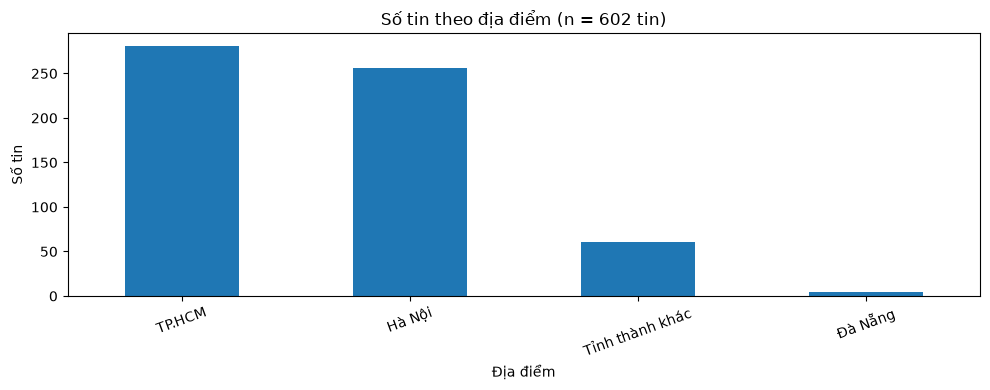

,Job_Count,Percent (%)
sql,320,53.16
python,285,47.34
machine_learning,154,25.58
excel,113,18.77
docker,106,17.61
git,101,16.78
power_bi,98,16.28
postgresql,90,14.95
oracle,90,14.95
java,89,14.78


Đã lưu biểu đồ: ..\reports\figures\eda_top15_skills.png


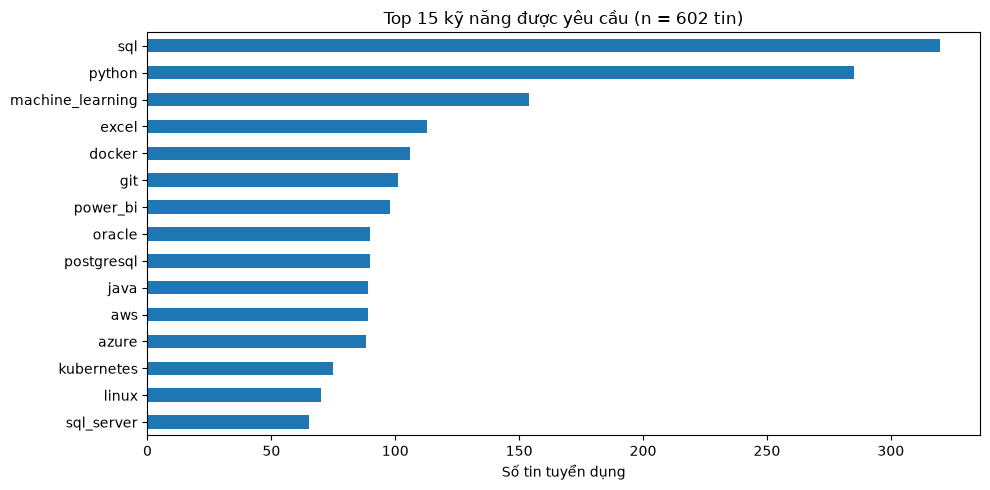

Kinh nghiệm (năm) — n_valid = 553, missing = 49


count    553.00
mean       2.55
std        1.64
min        0.00
25%        1.00
50%        3.00
75%        3.08
max       12.00
Name: Experience_Years, dtype: float64

Đã lưu biểu đồ: ..\reports\figures\eda_experience_distribution.png


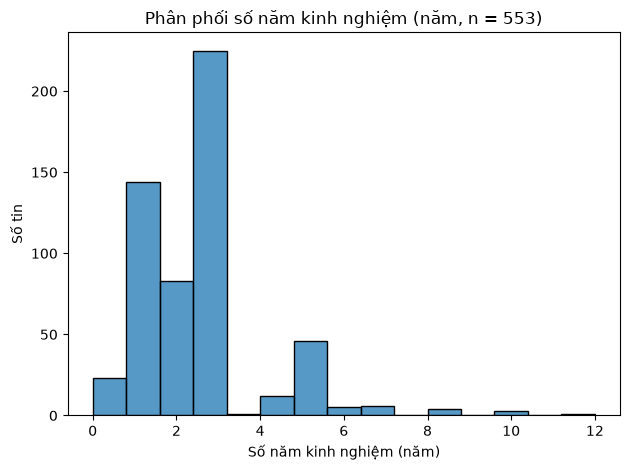

In [10]:
# EDA: Địa điểm, kỹ năng, Kinh nghiệm
df = pd.read_csv(CLEAN_PATH)
skill_cols = [c for c in df.columns if c.startswith("Skill_")]
print(f"Tổng số mẫu phân tích: n = {len(df)} tin tuyển dụng")

if "Location_Normalized" in df.columns:
    loc_tbl = df["Location_Normalized"].value_counts().to_frame("Job_Count")
    loc_tbl["Percent (%)"] = (loc_tbl["Job_Count"] / len(df) * 100).round(2)
    display(loc_tbl)
    ax = loc_tbl["Job_Count"].plot(kind="bar", figsize=(10, 4), title=f"Số tin theo địa điểm (n = {len(df)} tin)")
    plt.xlabel("Địa điểm")
    plt.ylabel("Số tin"); 
    plt.xticks(rotation=20)
    plt.tight_layout()
    save_fig("eda_location.png")
    plt.show()

if skill_cols:
    skill_counts = df[skill_cols].sum().sort_values(ascending=False).head(15)
    skill_tbl = skill_counts.to_frame("Job_Count")
    skill_tbl["Percent (%)"] = (skill_tbl["Job_Count"] / len(df) * 100).round(2)
    skill_tbl.index = skill_tbl.index.str.replace("Skill_", "", regex=False)
    display(skill_tbl)
    skill_tbl["Job_Count"].sort_values().plot(kind="barh", figsize=(10, 5), title=f"Top 15 kỹ năng được yêu cầu (n = {len(df)} tin)")
    plt.xlabel("Số tin tuyển dụng")
    plt.tight_layout()
    save_fig("eda_top15_skills.png")
    plt.show()

if "Experience_Years" in df.columns:
    exp_valid = df["Experience_Years"].dropna()
    print(f"Kinh nghiệm (năm) — n_valid = {len(exp_valid)}, missing = {df['Experience_Years'].isna().sum()}")
    display(exp_valid.describe().round(2))
    sns.histplot(exp_valid, bins=15)
    plt.title(f"Phân phối số năm kinh nghiệm (năm, n = {len(exp_valid)})")
    plt.xlabel("Số năm kinh nghiệm (năm)")
    plt.ylabel("Số tin")
    plt.tight_layout()
    save_fig("eda_experience_distribution.png")
    plt.show()


Phân bố Seniority_EDA (toàn tập, n = 602 ):


,Job_Count
Seniority_EDA,
Senior,152
Fresher,145
Middle,139
Junior,82
Lead,51
NaN,33


Số tin có thông tin lương định lượng: n = 166 / 602 (Negotiable: 435)


Luong_Min                          Luong_Max              \
                    count      median         mean     count      median   
Salary_Currency                                                            
SGD                     1      3500.0      3500.00         1      5000.0   
USD                    50      1000.0      1086.40        52      2000.0   
VND                   110  18000000.0  19357272.73       113  25000000.0   

                              
                        mean  
Salary_Currency               
SGD                  5000.00  
USD                  2009.62  
VND              29775516.23


Lương (triệu VNĐ/tháng) theo Seniority (n_valid = 153):


,count,min,median,mean,max,Đủ mẫu (n>=5)
Seniority_EDA,,,,,,
Fresher,41,0.5,19.00,19.79,43.75,True
Junior,25,10.5,20.00,21.02,33.75,True
Middle,38,16.0,30.00,33.40,85.00,True
Senior,35,13.5,36.25,39.26,81.25,True
Lead,14,16.0,40.00,41.66,81.25,True


d:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


Đã lưu biểu đồ: ..\reports\figures\salary_by_seniority.png


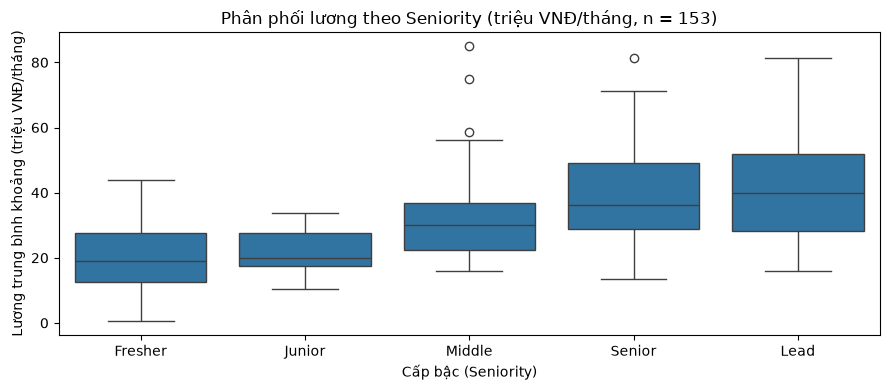


So sánh nhu cầu tuyển dụng & kinh nghiệm theo khu vực:


,Job_Count,Exp_Valid_n,Exp_Median_Years,Exp_Mean_Years
Location_Normalized,,,,
TP.HCM,281,267,3.00,2.44
Hà Nội,256,232,3.00,2.67
Đà Nẵng,4,4,2.54,2.25



So sánh mức lương (triệu VNĐ/tháng) theo khu vực:


,count,min,median,mean,max,Đủ mẫu (n>=5)
Location_Normalized,,,,,,
TP.HCM,69,0.50,31.25,32.15,81.25,True
Hà Nội,80,3.12,25.00,28.46,85.00,True
Đà Nẵng,1,68.75,68.75,68.75,68.75,False


LƯU Ý: Đà Nẵng chỉ có n = 1 mẫu lương (< 5), KHÔNG đủ cơ sở để kết luận mặt bằng lương.


d:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


Đã lưu biểu đồ: ..\reports\figures\salary_by_location.png


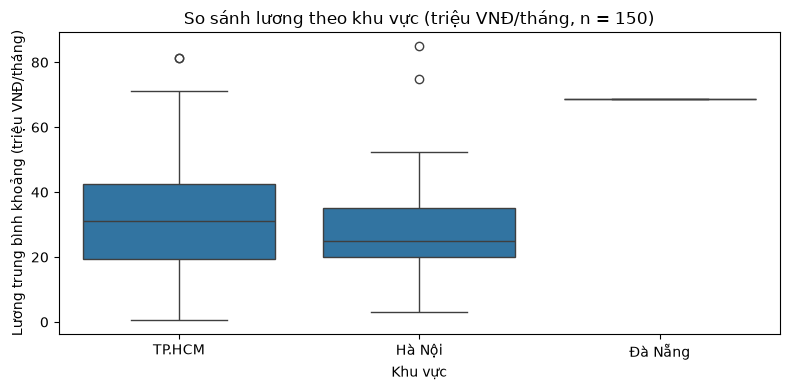

In [11]:
# EDA Lương theo đơn vị, chức vụ & So sánh các tỉnh thành
MIN_SAMPLE_NOTE = 5  # Ngưỡng tối thiểu nhận xét thống kê

def infer_seniority(row):
    title = str(row.get("job_title", "")).lower()
    exp = row.get("Experience_Years", np.nan)
    if any(k in title for k in ["intern", "thực tập", "fresher"]): return "Fresher"
    if any(k in title for k in ["lead", "manager", "trưởng phòng", "head"]): return "Lead"
    if "senior" in title or "sr." in title: return "Senior"
    if "middle" in title or "mid-level" in title: return "Middle"
    if "junior" in title or "jr." in title: return "Junior"
    if pd.notna(exp):
        if exp <= 1: return "Fresher"
        if exp <= 2: return "Junior"
        if exp <= 4: return "Middle"
        return "Senior"
    return np.nan

df["Seniority_EDA"] = df.apply(infer_seniority, axis=1)
print("Phân bố Seniority_EDA (toàn tập, n =", len(df), "):")
display(df["Seniority_EDA"].value_counts(dropna=False).to_frame("Job_Count"))

# Tách riêng theo từng loại tiền tệ
if {"Luong_Min", "Luong_Max", "Salary_Currency"}.issubset(df.columns):
    sal_cur = df.dropna(subset=["Luong_Min", "Luong_Max"], how="all").copy()
    print(f"Số tin có thông tin lương định lượng: n = {len(sal_cur)} / {len(df)} (Negotiable: {(df['Salary_Type']=='Negotiable').sum()})")
    display(sal_cur.groupby("Salary_Currency")[["Luong_Min", "Luong_Max"]].agg(["count", "median", "mean"]).round(2))

# Lương quy đổi VNĐ/tháng theo chức vụ
if "Luong_Mid_VND" in df.columns:
    sal_vnd = df.dropna(subset=["Luong_Mid_VND"]).copy()
    sal_vnd["Luong_Mid_Trieu"] = sal_vnd["Luong_Mid_VND"] / 1e6
    order = ["Fresher", "Junior", "Middle", "Senior", "Lead"]
    sen_stats = sal_vnd.groupby("Seniority_EDA")["Luong_Mid_Trieu"].agg(["count", "min", "median", "mean", "max"]).reindex(order).round(2)
    sen_stats["Đủ mẫu (n>=5)"] = sen_stats["count"].fillna(0) >= MIN_SAMPLE_NOTE
    print(f"\nLương (triệu VNĐ/tháng) theo Seniority (n_valid = {sal_vnd['Seniority_EDA'].notna().sum()}):")
    display(sen_stats)

    plt.figure(figsize=(9, 4))
    plot_sen = sal_vnd[sal_vnd["Seniority_EDA"].isin(order)]
    sns.boxplot(data=plot_sen, x="Seniority_EDA", y="Luong_Mid_Trieu", order=order)
    plt.title(f"Phân phối lương theo Seniority (triệu VNĐ/tháng, n = {len(plot_sen)})")
    plt.xlabel("Cấp bậc (Seniority)")
    plt.ylabel("Lương trung bình khoảng (triệu VNĐ/tháng)")
    plt.tight_layout()
    save_fig("salary_by_seniority.png")
    plt.show()

# So sánh Hà Nội vs TP.HCM vs Đà Nẵng
cities = ["TP.HCM", "Hà Nội", "Đà Nẵng"]
city_df = df[df["Location_Normalized"].isin(cities)].copy()
city_demand = city_df.groupby("Location_Normalized").agg(
    Job_Count=("url", "count"),
    Exp_Valid_n=("Experience_Years", "count"),
    Exp_Median_Years=("Experience_Years", "median"),
    Exp_Mean_Years=("Experience_Years", "mean"),
).reindex(cities).round(2)
print("\nSo sánh nhu cầu tuyển dụng & kinh nghiệm theo khu vực:")
display(city_demand)

if "Luong_Mid_VND" in df.columns:
    sal_city = sal_vnd[sal_vnd["Location_Normalized"].isin(cities)].copy()
    city_sal = sal_city.groupby("Location_Normalized")["Luong_Mid_Trieu"].agg(["count", "min", "median", "mean", "max"]).reindex(cities).round(2)
    city_sal["Đủ mẫu (n>=5)"] = city_sal["count"].fillna(0) >= MIN_SAMPLE_NOTE
    print("\nSo sánh mức lương (triệu VNĐ/tháng) theo khu vực:")
    display(city_sal)
    for c_name, row_c in city_sal.iterrows():
        if pd.isna(row_c["count"]) or row_c["count"] < MIN_SAMPLE_NOTE:
            print(f"LƯU Ý: {c_name} chỉ có n = {int(row_c['count'] or 0)} mẫu lương (< {MIN_SAMPLE_NOTE}), KHÔNG đủ cơ sở để kết luận mặt bằng lương.")

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=sal_city, x="Location_Normalized", y="Luong_Mid_Trieu", order=cities)
    plt.title(f"So sánh lương theo khu vực (triệu VNĐ/tháng, n = {len(sal_city)})")
    plt.xlabel("Khu vực")
    plt.ylabel("Lương trung bình khoảng (triệu VNĐ/tháng)")
    plt.tight_layout()
    save_fig("salary_by_location.png")
    plt.show()

,Job_Count
Role_Group,
Khác (Dev/IT khác),372
Data/Business Analyst,114
Data Scientist/AI,82
Data Engineer,34


Đã lưu biểu đồ: ..\reports\figures\skills_by_role_heatmap.png


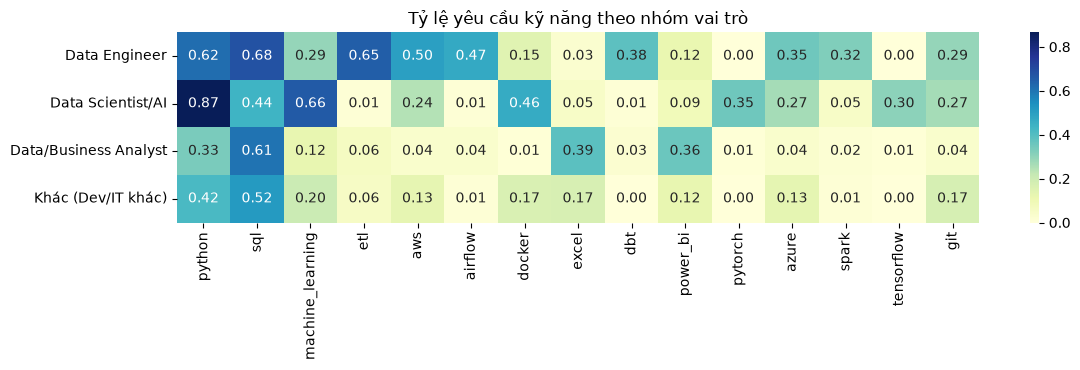

Lương (triệu VNĐ/tháng) theo vai trò — chỉ tin có lương số:


,count,median,mean,Đủ mẫu (n>=5)
Role_Group,,,,
Data Engineer,8,34.4,38.3,True
Data Scientist/AI,27,35.0,35.4,True
Data/Business Analyst,31,20.5,22.2,True
Khác (Dev/IT khác),100,27.5,29.7,True


In [12]:
# Phân tích theo kỹ năng đặc trưng & lương
def role_of(t):
    t = str(t).lower()
    if re.search(r"data engineer|analytics engineer|etl|big data|data platform", t): return "Data Engineer"
    if re.search(r"data scien|machine learning|\bai\b|\bml\b|deep learning|nlp|computer vision", t): return "Data Scientist/AI"
    if re.search(r"data analy|business analy|\bbi\b|business intelligence|phân tích|reporting|analyst", t): return "Data/Business Analyst"
    return "Khác (Dev/IT khác)"
df["Role_Group"] = df["job_title"].apply(role_of)
display(df["Role_Group"].value_counts().to_frame("Job_Count"))
role_skill = df.groupby("Role_Group")[skill_cols].mean()
role_skill.columns = [c.replace("Skill_","") for c in role_skill.columns]
top_sk_global = role_skill.max().sort_values(ascending=False).head(15).index
plt.figure(figsize=(12,3.8)); sns.heatmap(role_skill[top_sk_global], annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Tỷ lệ yêu cầu kỹ năng theo nhóm vai trò")
plt.ylabel("")
plt.tight_layout()
save_fig("skills_by_role_heatmap.png")
plt.show()
if "Luong_Mid_VND" in df.columns:
    rs = df.dropna(subset=["Luong_Mid_VND"]).assign(M=lambda d: d["Luong_Mid_VND"]/1e6).groupby("Role_Group")["M"].agg(["count","median","mean"]).round(1)
    rs["Đủ mẫu (n>=5)"] = rs["count"] >= 5
    print("Lương (triệu VNĐ/tháng) theo vai trò — chỉ tin có lương số:"); display(rs)

Feature matrix: 602 mẫu × 47 đặc trưng | Missing trước impute: 49
Đã lưu biểu đồ: ..\reports\figures\kmeans_elbow_silhouette.png


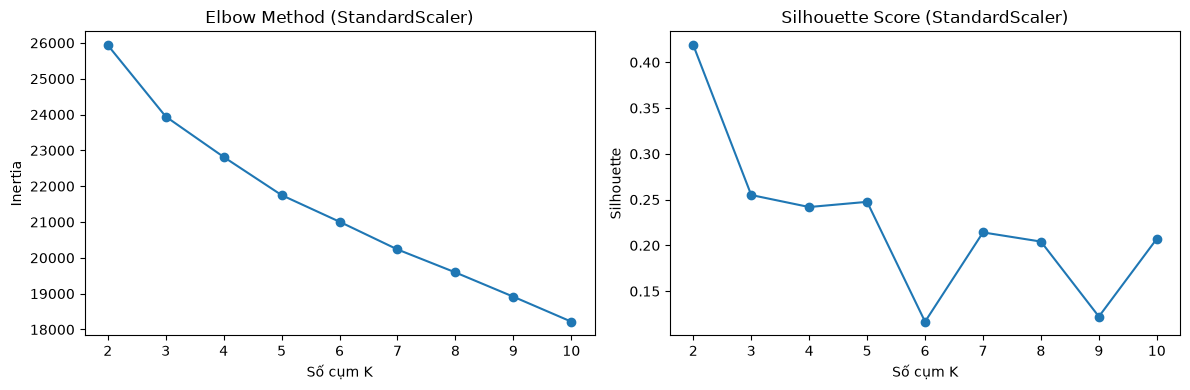

,K,Inertia,Silhouette
0,2,25936.95,0.4187
1,3,23944.00,0.2550
2,4,22815.77,0.2419
3,5,21750.88,0.2476
4,6,21007.74,0.1167
5,7,20234.03,0.2142
6,8,19592.58,0.2042
7,9,18914.98,0.1223
8,10,18218.42,0.2072


In [13]:
# clustering — K-Means 
from sklearn.preprocessing import StandardScaler

if "df" not in globals() or not any(c.startswith("Skill_") for c in df.columns):
    df = pd.read_csv(CLEAN_PATH)
skill_cols = [c for c in df.columns if c.startswith("Skill_")]

# chọn kỹ năng và kinh nghiệm
leak_or_id = {"Job_ID", "url", "URL_Goc", "Luong_Min", "Luong_Max", "Luong_Min_VND", "Luong_Max_VND", "Luong_Mid_VND", "Seniority_EDA", "Seniority_Target", "Cluster"}
cluster_features = [c for c in skill_cols if c not in leak_or_id]
if "Experience_Years" in df.columns:
    cluster_features.append("Experience_Years")

assert not (set(cluster_features) & leak_or_id), "Phát hiện cột ID/leakage trong feature matrix!"
X_cluster_raw = df[cluster_features].replace([np.inf, -np.inf], np.nan)
X_cluster_raw = X_cluster_raw.loc[:, X_cluster_raw.nunique(dropna=True) > 1]
print(f"Feature matrix: {X_cluster_raw.shape[0]} mẫu × {X_cluster_raw.shape[1]} đặc trưng | Missing trước impute: {int(X_cluster_raw.isna().sum().sum())}")

# chuẩn hóa StandardScaler
X_cluster_imp = SimpleImputer(strategy="median").fit_transform(X_cluster_raw)
X_cluster_scaled = StandardScaler().fit_transform(X_cluster_imp)

ks = list(range(2, min(10, len(X_cluster_scaled) - 1) + 1))
inertias, sils = [], []
for k in ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_cluster_scaled)
    inertias.append(model.inertia_)
    sils.append(silhouette_score(X_cluster_scaled, labels))

k_metrics = pd.DataFrame({"K": ks, "Inertia": np.round(inertias, 2), "Silhouette": np.round(sils, 4)})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set(title="Elbow Method (StandardScaler)", xlabel="Số cụm K", ylabel="Inertia")
ax[1].plot(ks, sils, marker="o"); ax[1].set(title="Silhouette Score (StandardScaler)", xlabel="Số cụm K", ylabel="Silhouette")
plt.tight_layout()
save_fig("kmeans_elbow_silhouette.png")
plt.show()
display(k_metrics)


Chọn K = 3 (Silhouette = 0.2550; 


,Job_Count,Percent (%)
Cluster,,
0,131,21.76
1,442,73.42
2,29,4.82


,Cluster,Job_Count,Percent (%),Exp_Valid_n,Exp_Mean_Years,Top_Skills
0,0,131,21.76,123,2.41,"docker (61%), python (60%), sql (59%), postgre..."
1,1,442,73.42,408,2.61,"sql (52%), python (40%), excel (25%), power_bi..."
2,2,29,4.82,22,2.19,"python (93%), machine_learning (90%), pytorch ..."


Đã lưu biểu đồ: ..\reports\figures\cluster_skills_heatmap.png


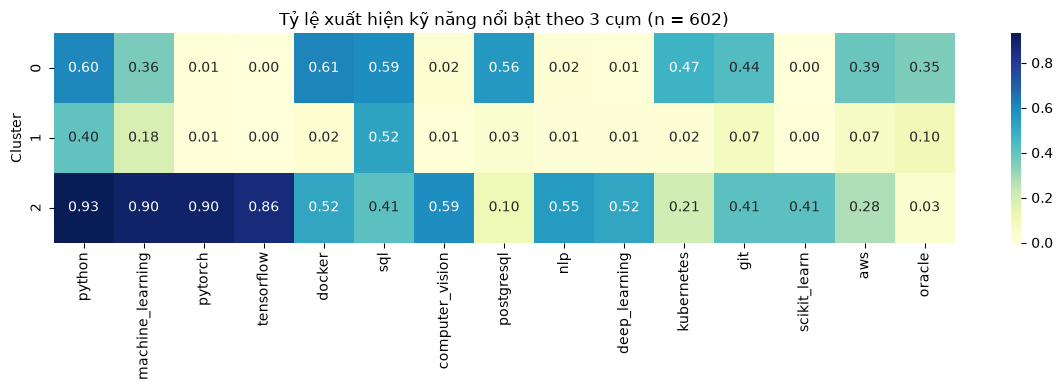

In [14]:
# chọn K có căn cứ (vì Elbow + đỉnh Silhouette ở K >= 3 hiển thị ở biểu đồ trước) 
cand = k_metrics[k_metrics["K"] >= 3]
CHOSEN_K = int(cand.loc[cand["Silhouette"].idxmax(), "K"]) 
chosen_sil = float(cand.loc[cand["Silhouette"].idxmax(), "Silhouette"])
print(f"Chọn K = {CHOSEN_K} (Silhouette = {chosen_sil:.4f}; ")

km = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=20)
df["Cluster"] = km.fit_predict(X_cluster_scaled)

size_tbl = df["Cluster"].value_counts().sort_index().to_frame("Job_Count")
size_tbl["Percent (%)"] = (size_tbl["Job_Count"] / len(df) * 100).round(2)
display(size_tbl)

sk_in_cluster = [c for c in X_cluster_raw.columns if c.startswith("Skill_")]
profile_skills = df.groupby("Cluster")[sk_in_cluster].mean()
exp_stats = df.groupby("Cluster")["Experience_Years"].agg(["count", "median", "mean"]).round(2)

# Diễn giải tự động từng cụm (chọn top 6 kỹ năng)
rows_summary = []
for cid in sorted(df["Cluster"].unique()):
    top_sk = profile_skills.loc[cid].sort_values(ascending=False).head(6)
    top_str = ", ".join([f"{k.replace('Skill_', '')} ({v*100:.0f}%)" for k, v in top_sk.items() if v > 0])
    n_c = int(size_tbl.loc[cid, "Job_Count"])
    rows_summary.append({
        "Cluster": cid,
        "Job_Count": n_c,
        "Percent (%)": round(n_c / len(df) * 100, 2),
        "Exp_Valid_n": int(exp_stats.loc[cid, "count"]),
        "Exp_Mean_Years": exp_stats.loc[cid, "mean"],
        "Top_Skills": top_str,
    })
cluster_summary = pd.DataFrame(rows_summary)
display(cluster_summary)

# Biểu đồ heatmap mô tả tỷ lệ kỹ năng nổi bật theo cụm
top_var_skills = profile_skills.max(axis=0).sort_values(ascending=False).head(15).index.tolist()
plt.figure(figsize=(12, 4))
hm = profile_skills[top_var_skills].copy()
hm.columns = [c.replace("Skill_", "") for c in hm.columns]
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title(f"Tỷ lệ xuất hiện kỹ năng nổi bật theo {CHOSEN_K} cụm (n = {len(df)})")
plt.ylabel("Cluster")
plt.tight_layout()
save_fig("cluster_skills_heatmap.png")
plt.show()


,Method,K,Silhouette,Davies-Bouldin (thấp tốt hơn)
0,K-Means,3,0.2550,2.5249
1,Hierarchical (Ward),3,0.1485,3.0305


Adjusted Rand Index K-Means vs Hierarchical: 0.4307
Đã lưu biểu đồ: ..\reports\figures\hierarchical_dendrogram.png


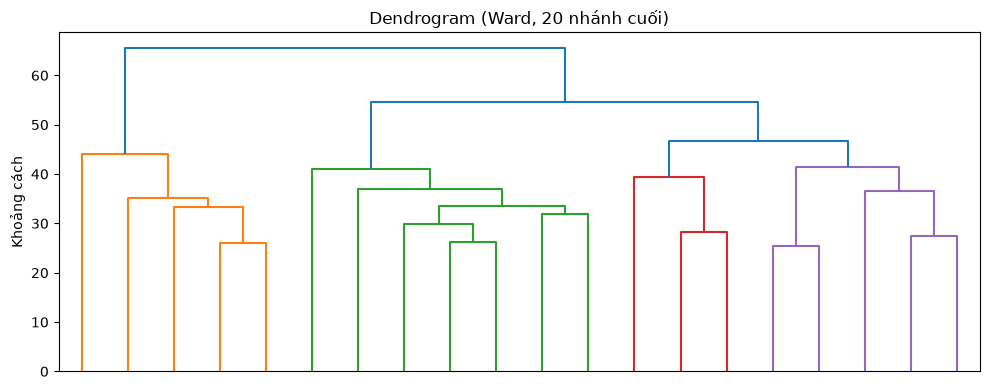

Cụm 0 (n=131): nổi bật so với toàn tập -> postgresql, kubernetes, docker, kafka
Cụm 1 (n=442): nổi bật so với toàn tập -> excel, power_bi, sas, vba
Cụm 2 (n=29): nổi bật so với toàn tập -> pytorch, tensorflow, machine_learning, computer_vision


In [15]:
# Hierarchical Clustering 
from scipy.cluster.hierarchy import linkage, dendrogram
agg = AgglomerativeClustering(n_clusters=CHOSEN_K, linkage="ward")
lab_h = agg.fit_predict(X_cluster_scaled)
cmp_cl = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical (Ward)"],
    "K": [CHOSEN_K, CHOSEN_K],
    "Silhouette": [silhouette_score(X_cluster_scaled, df["Cluster"]), silhouette_score(X_cluster_scaled, lab_h)],
    "Davies-Bouldin (thấp tốt hơn)": [davies_bouldin_score(X_cluster_scaled, df["Cluster"]), davies_bouldin_score(X_cluster_scaled, lab_h)],
}).round(4)
display(cmp_cl)
print("Adjusted Rand Index K-Means vs Hierarchical:", round(adjusted_rand_score(df["Cluster"], lab_h), 4))
Z = linkage(X_cluster_scaled, method="ward")
plt.figure(figsize=(10,4)); dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True)
plt.title("Dendrogram (Ward, 20 nhánh cuối)")
plt.ylabel("Khoảng cách")
plt.tight_layout()
save_fig("hierarchical_dendrogram.png")
plt.show()

# Đặt tên từng cụm
lift_prof = profile_skills / profile_skills.mean()
for cid in sorted(df["Cluster"].unique()):
    sig = (profile_skills.loc[cid] - profile_skills.mean()).sort_values(ascending=False).head(4)
    print(f"Cụm {cid} (n={int((df['Cluster']==cid).sum())}): nổi bật so với toàn tập -> " + ", ".join(k.replace('Skill_','') for k in sig.index))

In [16]:
# Association Rules — FP-Growth 
if skill_cols:
    transactions = df[skill_cols].astype(bool)
    transactions.columns = [c.replace("Skill_","") for c in transactions.columns]
    display(transactions.mean().sort_values(ascending=False).head(30).to_frame("Support"))
    MIN_SUPPORT = 0.03
    frequent = fpgrowth(transactions, min_support=MIN_SUPPORT, use_colnames=True)
    print("Số frequent itemsets:", len(frequent))
    rules = association_rules(frequent, metric="confidence", min_threshold=0.30)
    selected_rules = rules[rules["lift"] > 1.2].copy()
    
    # Với mỗi tập mục: giữ luật có confidence cao nhất -> bỏ luật đối xứng
    selected_rules["_k"] = selected_rules.apply(lambda r: frozenset(r["antecedents"] | r["consequents"]), axis=1)
    selected_rules = (selected_rules.sort_values(["confidence","lift"], ascending=False)
                      .drop_duplicates("_k").drop(columns="_k"))
    selected_rules["Luat"] = selected_rules.apply(lambda r: " + ".join(sorted(r["antecedents"])) + "  =>  " + " + ".join(sorted(r["consequents"])), axis=1)
    selected_rules = selected_rules.sort_values(["lift","confidence"], ascending=False)
    print(f"Luật sau lọc (lift > 1.2, bỏ đối xứng): {len(selected_rules)}")
    display(selected_rules[["Luat","support","confidence","lift","conviction"]].head(25).round(3))
else:
    print("Chưa có cột kỹ năng one-hot.")

,Support
sql,0.531561
python,0.473422
machine_learning,0.255814
excel,0.187708
docker,0.176080
git,0.167774
power_bi,0.162791
postgresql,0.149502
oracle,0.149502
java,0.147841


Số frequent itemsets: 258
Luật sau lọc (lift > 1.2, bỏ đối xứng): 190


,Luat,support,confidence,lift,conviction
514,python + tensorflow => pytorch,0.042,1.000,20.067,inf
528,machine_learning + python + tensorflow => py...,0.038,1.000,20.067,inf
509,tensorflow => pytorch,0.042,0.962,19.295,24.704
522,machine_learning + tensorflow => pytorch,0.038,0.958,19.231,22.804
215,docker + mongodb + postgresql => kubernetes,0.037,1.000,8.027,inf
495,redis => kafka,0.040,0.615,7.718,2.393
205,docker + mongodb => kubernetes,0.042,0.962,7.718,22.761
121,docker + oracle => kubernetes,0.033,0.909,7.297,9.630
440,azure + gcp => aws,0.050,1.000,6.764,inf
433,gcp => aws,0.063,0.905,6.120,8.948


In [17]:
# Classification qua nhãn 3 lớp từ chức vụ
SEN_MAP = {"Fresher":"Junior-", "Junior":"Junior-", "Middle":"Middle", "Senior":"Senior+", "Lead":"Senior+"}
df["Seniority_Target"] = df["Seniority_EDA"].map(SEN_MAP)
display(df["Seniority_Target"].value_counts(dropna=False))
TARGET = "Seniority_Target"

Seniority_Target
Junior-    227
Senior+    203
Middle     139
NaN         33
Name: count, dtype: int64

In [18]:
# Chia train/test và tiền xử lý
model_df=df.dropna(subset=[TARGET]).copy()
y=model_df[TARGET].astype(str)
X_cols=skill_cols.copy()
if "Location_Normalized" in model_df.columns: X_cols.append("Location_Normalized")
X=model_df[X_cols].copy()

counts=y.value_counts()
keep=y.isin(counts[counts>=2].index)
X,y=X.loc[keep],y.loc[keep]
display(y.value_counts())

if y.nunique()>=2 and len(y)>=10:
    X_train,X_test,y_train,y_test=train_test_split(
        X,y,test_size=0.2,random_state=RANDOM_STATE,stratify=y)
    numeric=[c for c in X.columns if c.startswith("Skill_")]
    categorical=[c for c in X.columns if c=="Location_Normalized"]
    prep=ColumnTransformer([
        ("num",SimpleImputer(strategy="median"),numeric),
        ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                         ("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical)
    ])
else:
    print("Không đủ dữ liệu/lớp để train-test stratified split.")

Seniority_Target
Junior-    227
Senior+    203
Middle     139
Name: count, dtype: int64

Best params: {'tree__ccp_alpha': np.float64(0.0019047619047619048)}
Đã lưu biểu đồ: ..\reports\figures\decision_tree_pruning.png


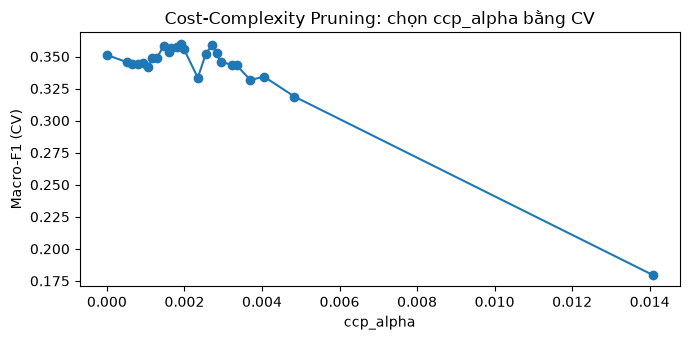

Số lá của cây tối ưu: 108


In [19]:
# cây quyết định 
if "X_train" in globals():
    path_model=Pipeline([("prep",prep),("tree",DecisionTreeClassifier(random_state=RANDOM_STATE,class_weight="balanced"))])
    path_model.fit(X_train,y_train)
    Xtr=path_model.named_steps["prep"].transform(X_train)
    pruning=DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(Xtr,y_train)
    alphas=np.unique(pruning.ccp_alphas)
    if len(alphas)>25: alphas=np.unique(np.quantile(alphas,np.linspace(0,1,25)))
    min_class=int(y_train.value_counts().min())
    if min_class>=2:
        cv=StratifiedKFold(n_splits=min(5,min_class),shuffle=True,random_state=RANDOM_STATE)
        grid=GridSearchCV(path_model,{"tree__ccp_alpha":alphas},scoring="f1_macro",cv=cv,n_jobs=1)
        grid.fit(X_train,y_train)
        dt_model=grid.best_estimator_
        print("Best params:",grid.best_params_)
    else: print("Một lớp có dưới 2 mẫu trong train; cần gộp/loại lớp hoặc thêm dữ liệu.")
    if 'grid' in globals():
        res = pd.DataFrame({"alpha": grid.cv_results_["param_tree__ccp_alpha"].astype(float), "f1_macro_cv": grid.cv_results_["mean_test_score"]})
        plt.figure(figsize=(7,3.5))
        plt.plot(res["alpha"], res["f1_macro_cv"], marker="o")
        plt.xlabel("ccp_alpha")
        plt.ylabel("Macro-F1 (CV)")
        plt.title("Cost-Complexity Pruning: chọn ccp_alpha bằng CV")
        plt.tight_layout()
        save_fig("decision_tree_pruning.png")
        plt.show()
        print("Số lá của cây tối ưu:", dt_model.named_steps["tree"].get_n_leaves())

In [20]:
# Mô hình đối sánh sử dụng Random Forest
if "X_train" in globals():
    rf_model=Pipeline([("prep",prep),("rf",RandomForestClassifier(
        n_estimators=300,random_state=RANDOM_STATE,class_weight="balanced",min_samples_leaf=2))])
    rf_model.fit(X_train,y_train)

In [21]:
# Mô hình đối sánh sử dụng Logistic Regression & KNN
if "X_train" in globals():
    lr_model = Pipeline([("prep", prep), ("lr", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_train, y_train)
    knn_model = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=7))]).fit(X_train, y_train)

Decision Tree (pruned)
              precision    recall  f1-score   support

     Junior-       0.40      0.42      0.41        45
      Middle       0.27      0.29      0.28        28
     Senior+       0.33      0.29      0.31        41

    accuracy                           0.34       114
   macro avg       0.33      0.33      0.33       114
weighted avg       0.34      0.34      0.34       114

Đã lưu biểu đồ: ..\reports\figures\confusion_matrix_Decision Tree (pruned).png


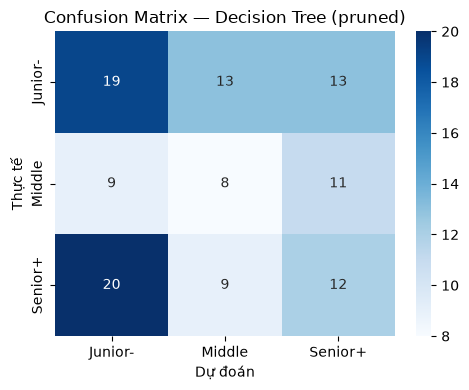

Random Forest
              precision    recall  f1-score   support

     Junior-       0.38      0.36      0.37        45
      Middle       0.32      0.43      0.36        28
     Senior+       0.44      0.37      0.40        41

    accuracy                           0.38       114
   macro avg       0.38      0.38      0.38       114
weighted avg       0.39      0.38      0.38       114

Đã lưu biểu đồ: ..\reports\figures\confusion_matrix_Random Forest.png


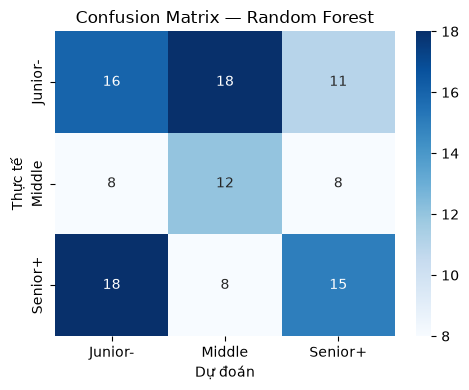

Logistic Regression
              precision    recall  f1-score   support

     Junior-       0.38      0.33      0.36        45
      Middle       0.22      0.36      0.27        28
     Senior+       0.45      0.32      0.37        41

    accuracy                           0.33       114
   macro avg       0.35      0.34      0.33       114
weighted avg       0.37      0.33      0.34       114

Đã lưu biểu đồ: ..\reports\figures\confusion_matrix_Logistic Regression.png


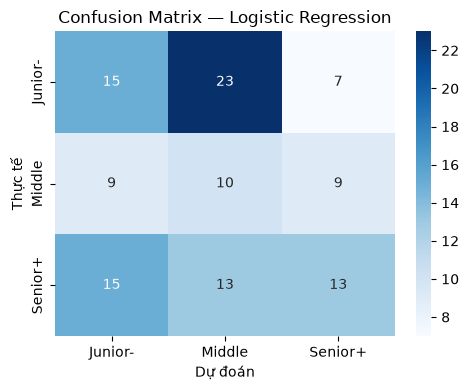

KNN (k=7)
              precision    recall  f1-score   support

     Junior-       0.41      0.53      0.47        45
      Middle       0.35      0.21      0.27        28
     Senior+       0.36      0.34      0.35        41

    accuracy                           0.39       114
   macro avg       0.38      0.36      0.36       114
weighted avg       0.38      0.39      0.38       114

Đã lưu biểu đồ: ..\reports\figures\confusion_matrix_KNN (k=7).png


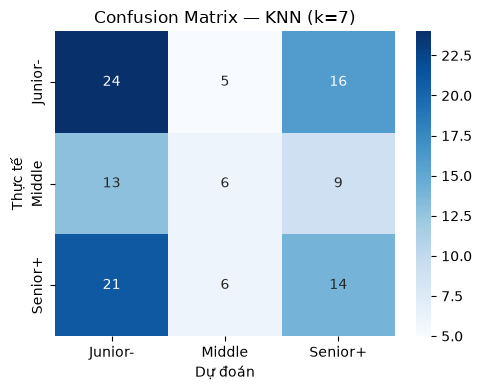

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,CV5_F1_macro_mean,CV5_F1_macro_std
1,Random Forest,0.3772,0.3793,0.3833,0.3772,0.3674,0.0331
3,KNN (k=7),0.3860,0.3752,0.3630,0.3609,0.3642,0.0247
2,Logistic Regression,0.3333,0.3501,0.3358,0.3329,0.3766,0.0336
0,Decision Tree (pruned),0.3421,0.3319,0.3335,0.3321,0.3402,0.0143


In [22]:
# Confusion Matrix, Precision, Recall, Macro F1 và so sánh các mô hình với nhau
def evaluate(model, name):
    pred = model.predict(X_test)
    print(name); print(classification_report(y_test, pred, zero_division=0))
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    labels = sorted(set(y_test) | set(pred))
    cm = confusion_matrix(y_test, pred, labels=labels)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.xlabel("Dự đoán")
    plt.ylabel("Thực tế")
    plt.title("Confusion Matrix — " + name)
    plt.tight_layout()
    save_fig(f"confusion_matrix_{name}.png")
    plt.show()
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision_macro": p, "Recall_macro": r, "F1_macro": f}

if "X_test" in globals():
    all_models = {"Decision Tree (pruned)": dt_model, "Random Forest": rf_model, "Logistic Regression": lr_model, "KNN (k=7)": knn_model}
    rows = [evaluate(m, n) for n, m in all_models.items()]
    cv_all = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    base_models = {"Decision Tree (pruned)": dt_model, "Random Forest": rf_model, "Logistic Regression": lr_model, "KNN (k=7)": knn_model}
    for r_ in rows:
        sc = cross_val_score(base_models[r_["Model"]], X, y, cv=cv_all, scoring="f1_macro", n_jobs=1)
        r_["CV5_F1_macro_mean"], r_["CV5_F1_macro_std"] = sc.mean(), sc.std()
    model_comparison = pd.DataFrame(rows).round(4).sort_values("F1_macro", ascending=False)
    display(model_comparison)

Đã lưu biểu đồ: ..\reports\figures\decision_tree_structure.png


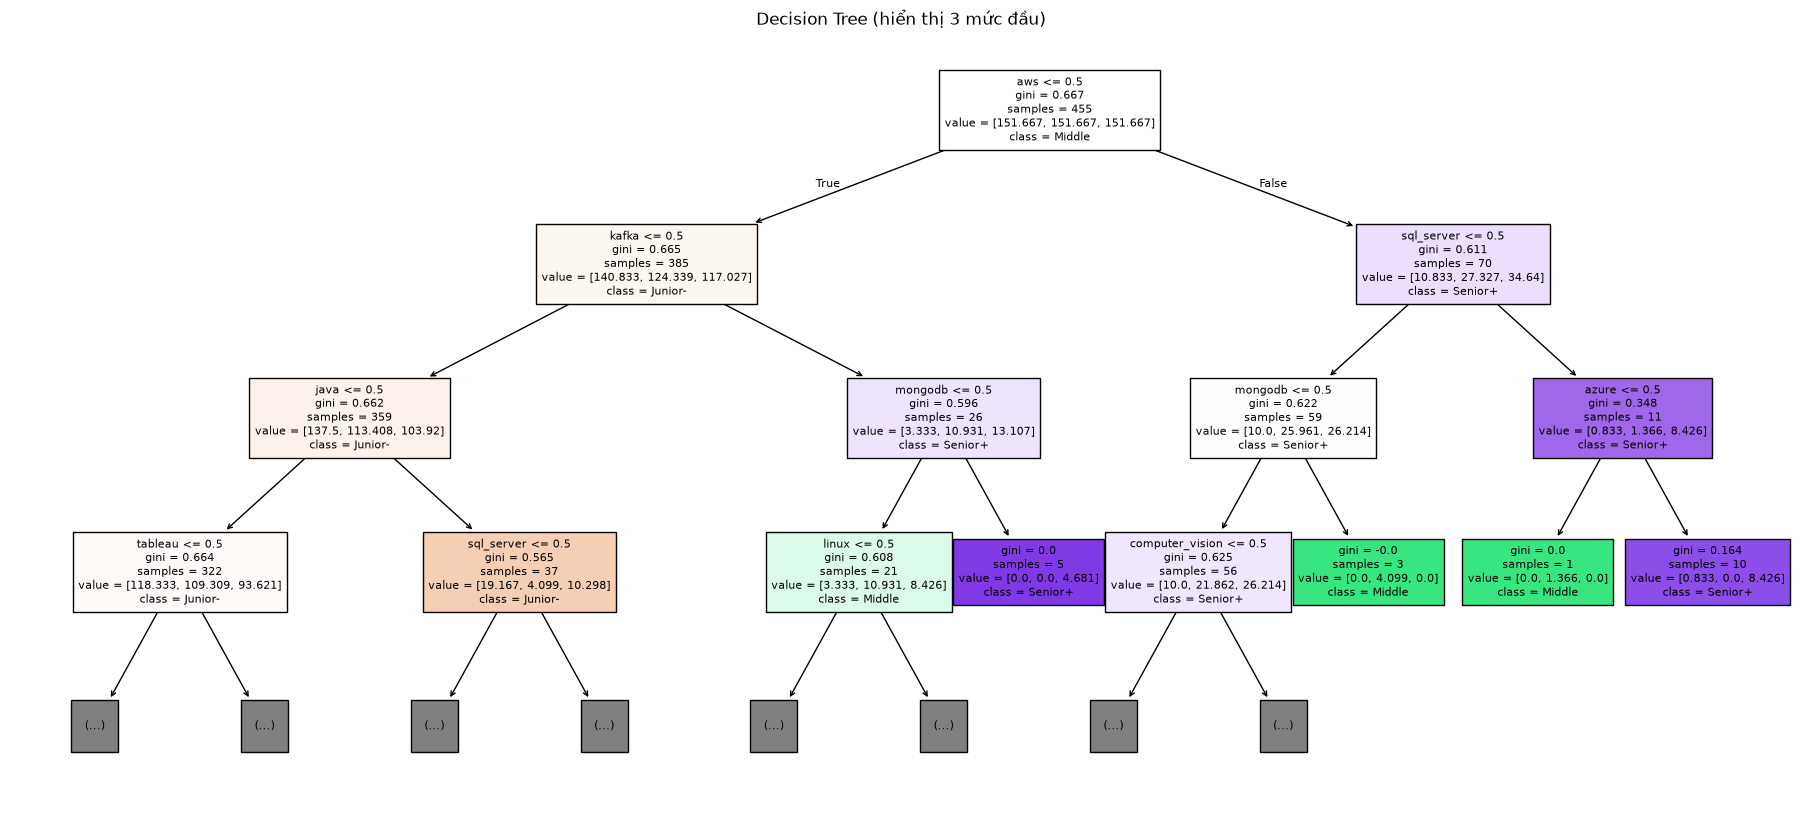

Đã lưu biểu đồ: ..\reports\figures\random_forest_feature_importance.png


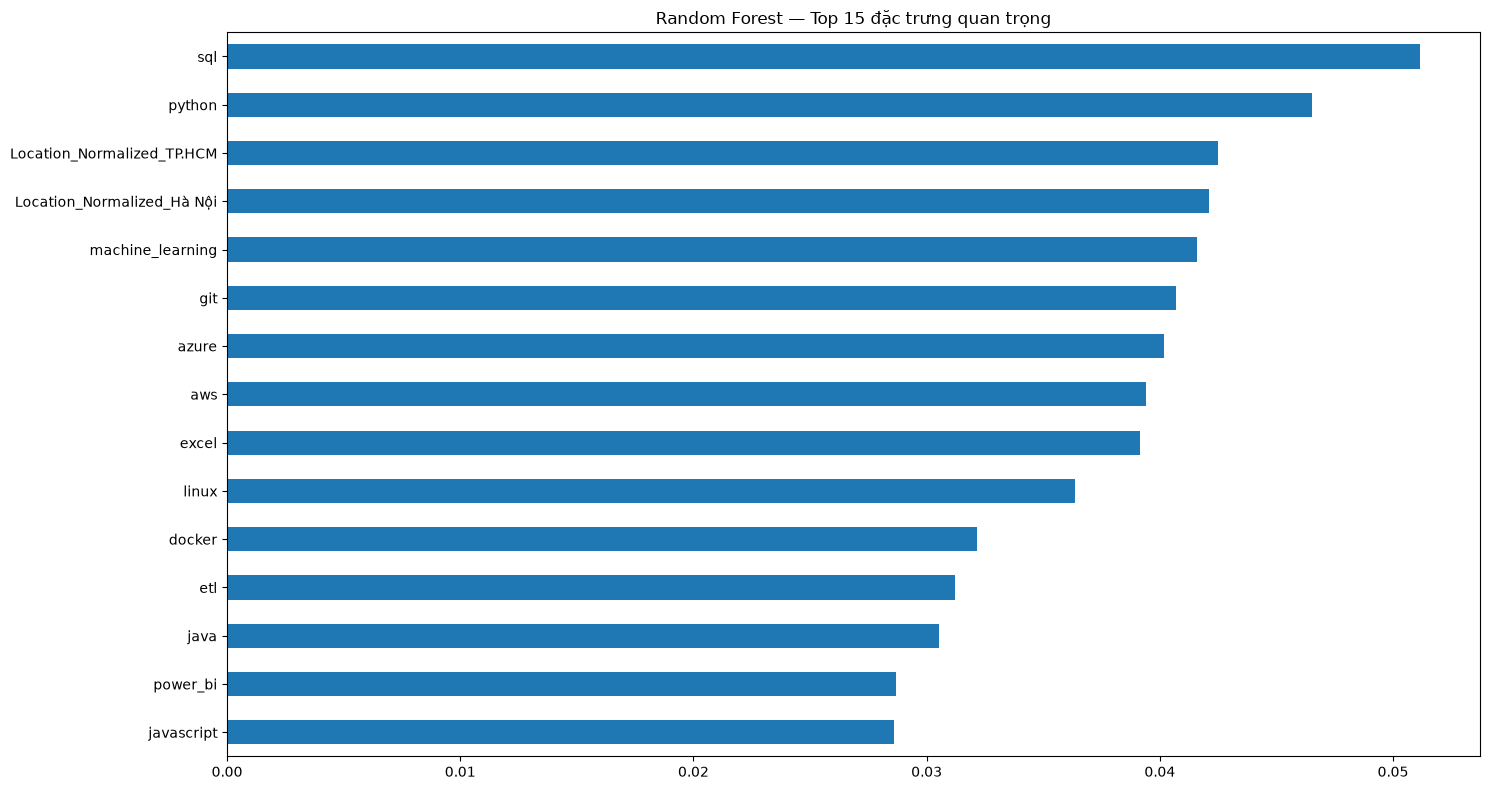

In [23]:
# MÔ hình cấu trúc cây quyết định & độ quan trọng đặc trưng
if "dt_model" in globals():
    feat_names = [n.split("__",1)[-1].replace("Skill_","") for n in dt_model.named_steps["prep"].get_feature_names_out()]
    tree = dt_model.named_steps["tree"]
    plt.figure(figsize=(23,10))
    plot_tree(tree, feature_names=feat_names, class_names=list(tree.classes_), max_depth=3, filled=True, fontsize=8)
    plt.title("Decision Tree (hiển thị 3 mức đầu)")
    save_fig("decision_tree_structure.png")
    plt.show()
    
    imp = pd.Series(rf_model.named_steps["rf"].feature_importances_, index=[n.split("__",1)[-1].replace("Skill_","") for n in rf_model.named_steps["prep"].get_feature_names_out()]).sort_values(ascending=False).head(15)
    imp.sort_values().plot(kind="barh", figsize=(15,8), title="Random Forest — Top 15 đặc trưng quan trọng")
    plt.tight_layout()
    save_fig("random_forest_feature_importance.png")
    plt.show()

In [24]:
# Luật kết hợp theo nhóm vai trò
def mine_rules(sub, min_support=0.06, min_conf=0.5, top=5):
    t = sub[skill_cols].astype(bool); t.columns = [c.replace("Skill_","") for c in t.columns]
    fi = fpgrowth(t, min_support=min_support, use_colnames=True)
    if fi.empty: return pd.DataFrame()
    r = association_rules(fi, metric="confidence", min_threshold=min_conf)
    r = r[r["lift"] > 1.2].copy()
    if r.empty: return r
    r["_k"] = r.apply(lambda x: frozenset(x["antecedents"] | x["consequents"]), axis=1)
    r = r.sort_values(["confidence","lift"], ascending=False).drop_duplicates("_k")
    r["Luat"] = r.apply(lambda x: " + ".join(sorted(x["antecedents"])) + "  =>  " + " + ".join(sorted(x["consequents"])), axis=1)
    return r.sort_values("lift", ascending=False)[["Luat","support","confidence","lift"]].head(top).round(3)

role_rules = {}
for role in ["Data/Business Analyst", "Data Scientist/AI", "Khác (Dev/IT khác)"]:
    sub = df[df["Role_Group"] == role]
    res = mine_rules(sub)
    print(f"\n=== {role} (n = {len(sub)}) ===")
    if res.empty: print("Không có luật đạt ngưỡng (support>=0.06, conf>=0.5, lift>1.2)")
    else: display(res); role_rules[role] = res.assign(Role_Group=role)
if role_rules: pd.concat(role_rules.values()).to_csv(DATA/"association_rules_by_role.csv", index=False, encoding="utf-8-sig")


=== Data/Business Analyst (n = 114) ===


,Luat,support,confidence,lift
51,oracle + power_bi + sql => tableau,0.070,1.0,7.600
81,machine_learning + sql => power_bi + python,0.079,1.0,4.957
24,tableau => oracle,0.079,0.6,4.275
72,machine_learning + sql => python,0.079,1.0,3.000
70,machine_learning + power_bi => python,0.088,1.0,3.000



=== Data Scientist/AI (n = 82) ===


,Luat,support,confidence,lift
22585,docker + go + machine_learning => java + pos...,0.061,1.0,16.4
20611,kubernetes + machine_learning + postgresql =>...,0.061,1.0,16.4
20812,kubernetes + machine_learning + postgresql + p...,0.061,1.0,16.4
20857,docker + kubernetes + machine_learning + postg...,0.061,1.0,16.4
20911,docker + kubernetes + machine_learning + postg...,0.061,1.0,16.4



=== Khác (Dev/IT khác) (n = 372) ===


,Luat,support,confidence,lift
47,redis => kafka,0.062,0.657,6.790
26,kubernetes + sql => docker,0.062,0.920,5.520
37,aws => azure,0.089,0.688,5.115
23,kubernetes + postgresql => docker,0.067,0.806,4.839
19,kubernetes => docker,0.102,0.745,4.471


In [25]:
# Xác định độ ổn định của cụm bằng cách so sánh các biến thể khác nhau của dữ liệu đầu vào
from sklearn.decomposition import TruncatedSVD
Xb = X_cluster_raw[[c for c in X_cluster_raw.columns if c.startswith("Skill_")]].values.astype(float)
variants = {"Chính (scale, +Experience)": X_cluster_scaled, "Chỉ kỹ năng, không scale": Xb,
            "SVD(10) trên kỹ năng": TruncatedSVD(n_components=10, random_state=RANDOM_STATE).fit_transform(Xb)}
rows = []
for name, Xv in variants.items():
    lab = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=20).fit_predict(Xv)
    rows.append({"Biến thể": name, "Silhouette": silhouette_score(Xv, lab), "Davies-Bouldin": davies_bouldin_score(Xv, lab),
                 "ARI so với cụm chính": adjusted_rand_score(df["Cluster"], lab), "Kích thước cụm": sorted(np.bincount(lab).tolist(), reverse=True)})
stab = pd.DataFrame(rows); stab[["Silhouette","Davies-Bouldin","ARI so với cụm chính"]] = stab[["Silhouette","Davies-Bouldin","ARI so với cụm chính"]].round(4)
display(stab); stab.to_csv(DATA/"cluster_stability.csv", index=False, encoding="utf-8-sig")

,Biến thể,Silhouette,Davies-Bouldin,ARI so với cụm chính,Kích thước cụm
0,"Chính (scale, +Experience)",0.2550,2.5249,1.0000,"[442, 131, 29]"
1,"Chỉ kỹ năng, không scale",0.1216,2.6510,0.3483,"[272, 223, 107]"
2,SVD(10) trên kỹ năng,0.1687,1.9281,0.3060,"[259, 228, 115]"


Parse được: 218 / 602 | từ 2026-10-05 đến 2026-11-16
Đã lưu biểu đồ: ..\reports\figures\job_posts_by_week.png


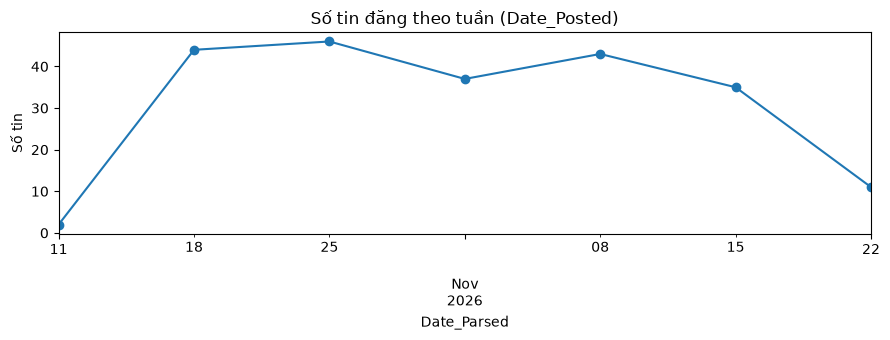

Đã lưu biểu đồ: ..\reports\figures\skills_by_keyword_heatmap.png


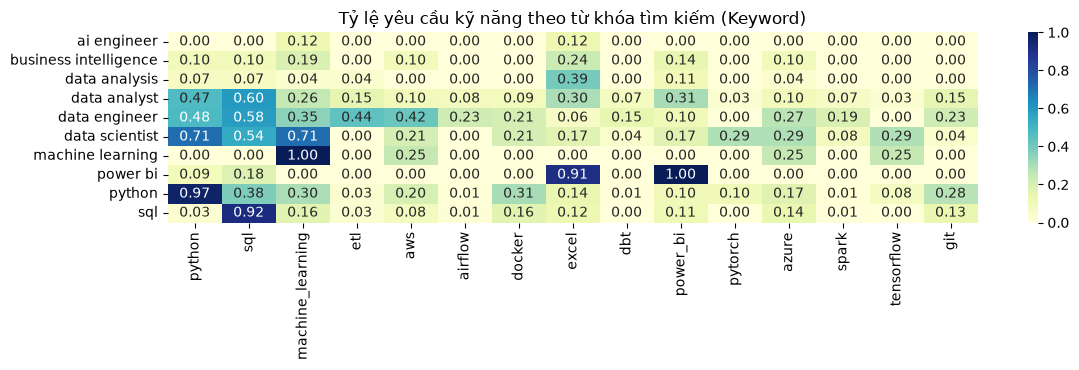

Role_Group             Data Engineer  Data Scientist/AI  \
Keyword                                                   
ai engineer                        0                  2   
business intelligence              0                  1   
data analysis                      0                  0   
data analyst                      12                  7   
data engineer                     22                  5   
data scientist                     0                 16   
machine learning                   0                  3   
power bi                           0                  0   
python                             0                 46   
sql                                0                  2   

Role_Group             Data/Business Analyst  Khác (Dev/IT khác)  
Keyword                                                           
ai engineer                                0                  15  
business intelligence                     11                   9  
data analysis          

In [26]:
# Xu hướng thời gian và kỹ năng theo Keyword tìm kiếm
df["Date_Parsed"] = pd.to_datetime(df["Date_Posted"], errors="coerce")
print("Parse được:", int(df["Date_Parsed"].notna().sum()), "/", len(df), "| từ", df["Date_Parsed"].min().date(), "đến", df["Date_Parsed"].max().date())
wk = df.dropna(subset=["Date_Parsed"]).set_index("Date_Parsed").resample("W").size()
plt.figure(figsize=(9,3.5))
wk.plot(marker="o")
plt.title("Số tin đăng theo tuần (Date_Posted)")
plt.ylabel("Số tin")
plt.tight_layout()
save_fig("job_posts_by_week.png")
plt.show()

kw_skill = df.groupby("Keyword")[skill_cols].mean(); kw_skill.columns = [c.replace("Skill_","") for c in kw_skill.columns]
plt.figure(figsize=(12,3.8))
sns.heatmap(kw_skill[top_sk_global], annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Tỷ lệ yêu cầu kỹ năng theo từ khóa tìm kiếm (Keyword)")
plt.ylabel("")
plt.tight_layout()
save_fig("skills_by_keyword_heatmap.png")
plt.show()
print(pd.crosstab(df["Keyword"], df["Role_Group"]))

In [27]:
# Xuất kết quã
if "skill_counts" in globals(): skill_counts.to_csv(DATA/"top_skills.csv", header=["Job_Count"], encoding="utf-8-sig")
if "selected_rules" in globals() and not selected_rules.empty:
    selected_rules.drop(columns=["antecedents","consequents"]).to_csv(DATA/"association_rules.csv", index=False, encoding="utf-8-sig")
if "cluster_summary" in globals(): cluster_summary.to_csv(DATA/"cluster_summary.csv", index=False, encoding="utf-8-sig")
if "model_comparison" in globals(): model_comparison.to_csv(DATA/"model_comparison.csv", index=False, encoding="utf-8-sig")
if "role_skill" in globals(): role_skill.to_csv(DATA/"skill_by_role.csv", encoding="utf-8-sig")
print("Đã xuất CSV vào", DATA.resolve(), "và hình vào", FIG_DIR.resolve())

Đã xuất CSV vào D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\data và hình vào D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\reports\figures
